In [41]:
%matplotlib widget
import importlib
import numpy as np
import scipy as sc
from scipy.special import jv
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import mpmath
from mpmath import *
import time
import pandas as pd
import matplotlib
import matplotlib.image
import matplotlib.lines as mlines
import matplotlib.patches as mpatches




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation')
from AR_interpolations_func import *
import AR_interpolations_func
importlib.reload(AR_interpolations_func)
from AR_interpolations_func  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation')
from AR_interpolations_plotting import *
import AR_interpolations_plotting
importlib.reload(AR_interpolations_plotting)
from AR_interpolations_plotting  import *



fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

## Get Simulation Data

In [42]:
path1 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet'
sample_name = r'\Sapphire'
dir_root_v3 = path1 + sample_name + r'\AR_estimation\Simulations_treated'
fname_data_simu = 'Simulation_treated.csv'


kernel_list = ['linear','thin_plate_spline' ,'cubic' ,'quintic' , 'multiquadric', 'gaussian','inverse_quadratic' ]
#kernel = 'thin_plate_spline'
kernel = 'linear'

Simu_data, Lda_RBF, E_RBF, W_RBF, Aire_RBF = get_simu_data_and_interpolate(dir_root_v3, fname_data_simu, kernel=kernel)

h_1D = 21

## Get Experimental Data

In [43]:
dir_root_ND = path1 + sample_name + r'\AR_estimation\ND_measurements'
fname_Exp = 'Nd_measurements_data.dat'
Exp_data = get_ND_measures(dir_root_ND, fname_Exp)

# for key in Exp_data :
#     print('----------------------------------------------')
#     for kkey in Exp_data[key] :
#         print(kkey, '///',  Exp_data[key][kkey])


## Estimate AR

In [44]:
d_guess, h_guess = 100, 25 #initial (D,h) guess in nm

AR_estimation_1D_Lda_SPR(Exp_data, Lda_RBF, h=h_1D)
AR_estimation_1D_Aire_SPR(Exp_data, Aire_RBF, h=h_1D)
AR_estimation_2D(Exp_data, Lda_RBF, Aire_RBF, d_guess=d_guess, h_guess=h_guess)

Gamma_surf_estimation(Exp_data, W_RBF)

Erreur de convergence 1D sur 2.3 zone-Sylvie NDas58 avec le paramètre de fit : SPR position
Erreur de convergence 1D sur 2.3 zone-Sylvie NDas73 avec le paramètre de fit : SPR position
Erreur de convergence 1D sur 2.3 zone-Sylvie NDbs02 avec le paramètre de fit : SPR position
Erreur de convergence 1D sur 2.3 zone-Sylvie NDbs14 avec le paramètre de fit : SPR position
Erreur de convergence 1D sur 2.3 zone1 NDe avec le paramètre de fit : SPR position
Erreur de convergence 1D sur 2.3 zone1 NDf avec le paramètre de fit : SPR position
Erreur de convergence 1D sur 2.3 zone2 NDa avec le paramètre de fit : SPR position
Erreur de convergence 1D sur 2.3 zone2 NDb avec le paramètre de fit : SPR position
Erreur de convergence 1D sur 2.3 zone2 NDc avec le paramètre de fit : SPR position
Erreur de convergence 1D sur 2.3 zone2 NDe avec le paramètre de fit : SPR position
Erreur de convergence 1D sur 2.3 zone2 NDf avec le paramètre de fit : SPR position
Erreur de convergence 2D sur : 2.3 zone-Sylvie NDbs

## Compute Gamma_surf

## Save data

In [45]:
dir_save_data = path1 + sample_name + r'\AR_estimation\ND_measurements_AR_treated'

fname_1D = '1D_AR_interpolation_python_approach_h_{}.csv'.format(h_1D)
save_1D_interpolation_to_csv(Exp_data, dir_save_data, fname_1D, h_1D)


fname_2D = '2D_AR_interpolation_python_approach.csv'.format(h_1D)
save_2D_interpolation_to_csv(Exp_data, dir_save_data, fname_2D)

fname_pickle = 'Treated_data_AR_interpolated'
save_treated_data_dic(Exp_data, dir_save_data, fname_pickle)

<>:12: SyntaxWarning: invalid escape sequence '\l'
<>:12: SyntaxWarning: invalid escape sequence '\l'
C:\Users\nberr\AppData\Local\Temp\ipykernel_18820\2699237074.py:12: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel('$\lambda_{SPR}$ (nm)')


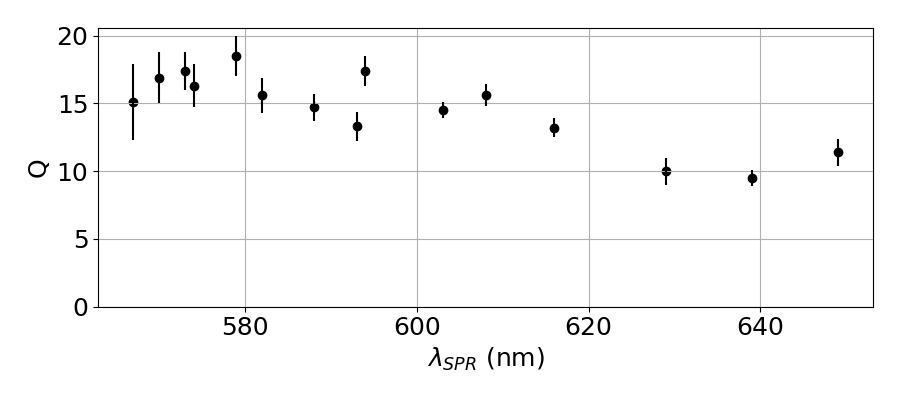

In [46]:
fig, ax = plt.subplots(figsize = (9,4))

for key in Exp_data :
    spectra = Exp_data[key]

    if spectra['Q'] != 0 :
            
        ax.scatter(spectra['lda_SPR'], spectra['Q'], c = 'black')
        ax.errorbar(spectra['lda_SPR'], spectra['Q'], yerr = spectra['Q_err'], color='black')
        

ax.set_xlabel('$\lambda_{SPR}$ (nm)')
ax.set_ylabel('Q')
ax.set_ylim(bottom = 0)
ax.grid()
plt.tight_layout()
plt.show()
fig.patch.set_facecolor( '#FF000000' )
# os.chdir(r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Quartz')

# plt.savefig('test.png')
# plt.savefig('test.pdf')

In [47]:
for key in Exp_data :
    spectra = Exp_data[key] 
    for kkey in spectra :
        print(kkey)

ND_name
AR
zone
name
date
lda_SPR
E_SPR
w_SPR
Aire_SPR
AR_estim_1D h = 25 nm
D_estimated_1D (h = 25 nm)
AR_estim_1D h = 20 nm
D_estimated_1D (h = 20 nm)
Gsurf_estimated
lambda_probe
polar
tau
tau_err
T
T_err
phi
phi_err
f1
f1_red_1D_est
Q
Q_err
tau2
tau2_err
T2
T2_err
phi2
phi2_err
Q2
Q2_err
f2
f2_red_1D_aire
1D_estimation
1D_estimation_Aire_SPR
2D_estimation
ND_name
AR
zone
name
date
lda_SPR
E_SPR
w_SPR
Aire_SPR
AR_estim_1D h = 25 nm
D_estimated_1D (h = 25 nm)
AR_estim_1D h = 20 nm
D_estimated_1D (h = 20 nm)
Gsurf_estimated
lambda_probe
polar
tau
tau_err
T
T_err
phi
phi_err
f1
f1_red_1D_est
Q
Q_err
tau2
tau2_err
T2
T2_err
phi2
phi2_err
Q2
Q2_err
f2
f2_red_1D_aire
1D_estimation
1D_estimation_Aire_SPR
2D_estimation
ND_name
AR
zone
name
date
lda_SPR
E_SPR
w_SPR
Aire_SPR
AR_estim_1D h = 25 nm
D_estimated_1D (h = 25 nm)
AR_estim_1D h = 20 nm
D_estimated_1D (h = 20 nm)
Gsurf_estimated
lambda_probe
polar
tau
tau_err
T
T_err
phi
phi_err
f1
f1_red_1D_est
Q
Q_err
tau2
tau2_err
T2
T2_err
phi2
ph

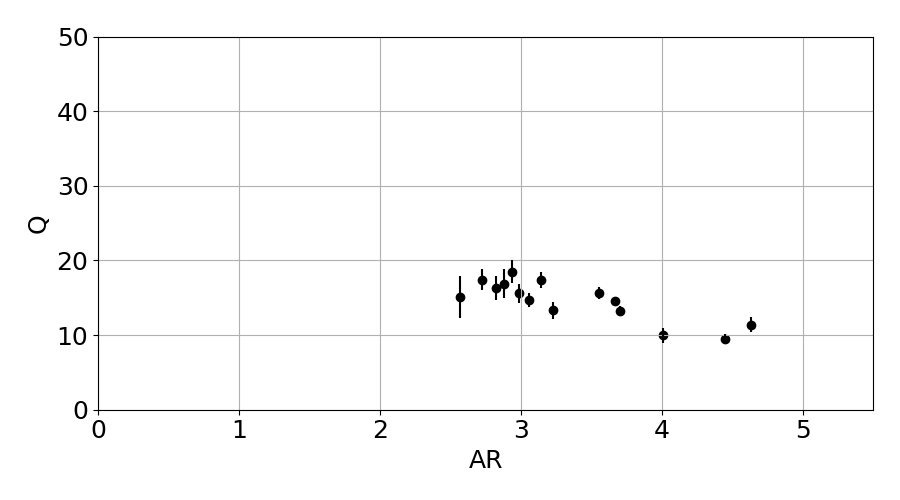

In [48]:
fig, ax = plt.subplots(figsize = (9,5))


estimation_key = '1D_estimation_Aire_SPR'

for key in Exp_data :
    spectra = Exp_data[key]

    if spectra['Q'] != 0 and spectra[estimation_key]['AR'] != 0 :
            
        # ax.scatter(spectra['1D_estimation_Aire_SPR']['AR'], spectra['Q'], c = 'black')
        # ax.errorbar(spectra['1D_estimation_Aire_SPR']['AR'], spectra['Q'], yerr = spectra['Q_err'], color='black')
        ax.scatter(spectra[estimation_key]['AR'], spectra['Q'], c = 'black')
        ax.errorbar(spectra[estimation_key]['AR'], spectra['Q'], yerr = spectra['Q_err'], color='black')
        

ax.set_xlabel('AR')
ax.set_ylabel('Q')
ax.set_ylim((0, 50))
ax.set_xlim((0, 5.5))
ax.grid()
#plt.legend()

plt.tight_layout()
plt.show()